# US15

## 1. Detailed Description

The aim is to analyse the annual profit of a specific railway station, providing simple statistical indicators to help understand its financial performance over time.

Concepts used:

    Profit: Difference between Revenues and Expenses.

    Mean: Average value of annual profits.

    Standard deviation: Measures the variation of profits in relation to the average.

    Median: The centre value of the ordered profits.

    Mode: Value that is repeated most often.

    Outliers: Profits far outside the normal pattern, detected by statistical rules (IQR).

## 2.Code

Média: 11566.76
Desvio Padrão: 12486.26
Mediana: 7564.43
Moda: 655.76
Ano mais lucrativo:
Year       2023.0
Profit    39684.9
Name: 8, dtype: float64

Ano menos lucrativo:
Year      2015.00
Profit     655.76
Name: 0, dtype: float64


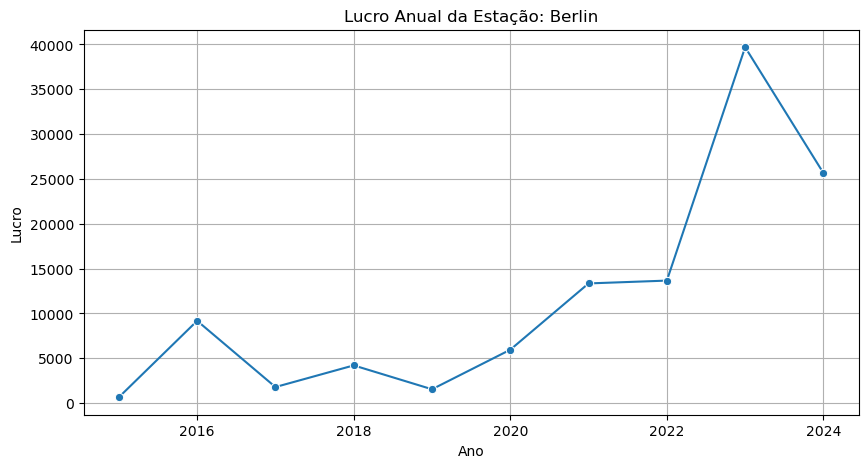

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Stations_Data.csv', sep=';')
df['Revenues'] = df['Revenues'].str.replace(',', '.').astype(float)
df['Expenses'] = df['Expenses'].str.replace(',', '.').astype(float)
df['Profit'] = df['Revenues'] - df['Expenses']
df.head()

station_name = "Berlin"  # Podes mudar para outra estação
station_df = df[df['Station'] == station_name]

annual_profit = station_df.groupby('Year')['Profit'].sum().reset_index()
annual_profit

mean_val = annual_profit['Profit'].mean()
std_val = annual_profit['Profit'].std()
median_val = annual_profit['Profit'].median()
mode_val = annual_profit['Profit'].mode()[0]

print(f"Média: {mean_val:.2f}")
print(f"Desvio Padrão: {std_val:.2f}")
print(f"Mediana: {median_val:.2f}")
print(f"Moda: {mode_val:.2f}")

Q1 = annual_profit['Profit'].quantile(0.25)
Q3 = annual_profit['Profit'].quantile(0.75)
IQR = Q3 - Q1
outliers = annual_profit[(annual_profit['Profit'] < Q1 - 1.5 * IQR) | (annual_profit['Profit'] > Q3 + 1.5 * IQR)]
outliers

most_profitable = annual_profit.loc[annual_profit['Profit'].idxmax()]
least_profitable = annual_profit.loc[annual_profit['Profit'].idxmin()]

print("Ano mais lucrativo:")
print(most_profitable)

print("\nAno menos lucrativo:")
print(least_profitable)

plt.figure(figsize=(10, 5))
sns.lineplot(data=annual_profit, x='Year', y='Profit', marker='o')
plt.title(f"Lucro Anual da Estação: {station_name}")
plt.xlabel("Ano")
plt.ylabel("Lucro")
plt.grid(True)
plt.show()

## 3. Interpreting the results

    The mean shows the typical profit for the season.

    The standard deviation indicates whether there were years with profits very different from the average.

    The median and mode help you see if the data is balanced or if there are any unusual years.

    Outliers represent exceptional years, which should be analysed separately.

    The most and least profitable years show the best and worst financial performance of the season.

    Importance in the project: This analysis allows us to make more informed decisions in the railway simulator, such as knowing where to invest, which stations need attention and how to improve the operation based on real data.

# US16

## 1. Detailed Description of the Objectives and Theoretical Concepts


### 1.1 Objectives

The purpose of this analysis is to perform a comparative evaluation of passenger arrivals at various train stations. The user is presented with a boxplot that highlights the distribution of passenger volumes across multiple stations, thereby supporting the identification of the most and least frequented locations.

1.2 Theoretical Concepts
------------------------

### 1.2.1 Boxplot Representation

Boxplots are a statistical visualization tool used to display the distribution and variability of a dataset. The box represents the interquartile range , while the horizontal line inside the box indicates the median. Whiskers extend to the minimum and maximum values excluding outliers, which are shown as individual points. This graphical approach allows for direct comparison of central tendencies, spread, and the presence of outliers between different groups—in this case, train stations.

### 1.2.2 Descriptive Statistics

To complement the visual representation, the following statistics are computed for each station: • Count: Total number of data entries per station. • Mean and Median: the mean is the average value of passengers and median is the value that appears exacly in the middle of the ordered data , they are both useful for understanding typical passenger volumes. • Standard Deviation: Indicates the degree of variation in passenger arrivals. • Quartiles: Segment the data into intervals to observe data spread. • Minimum and Maximum: Help identify extremes and potential anomalies

## 2.Code

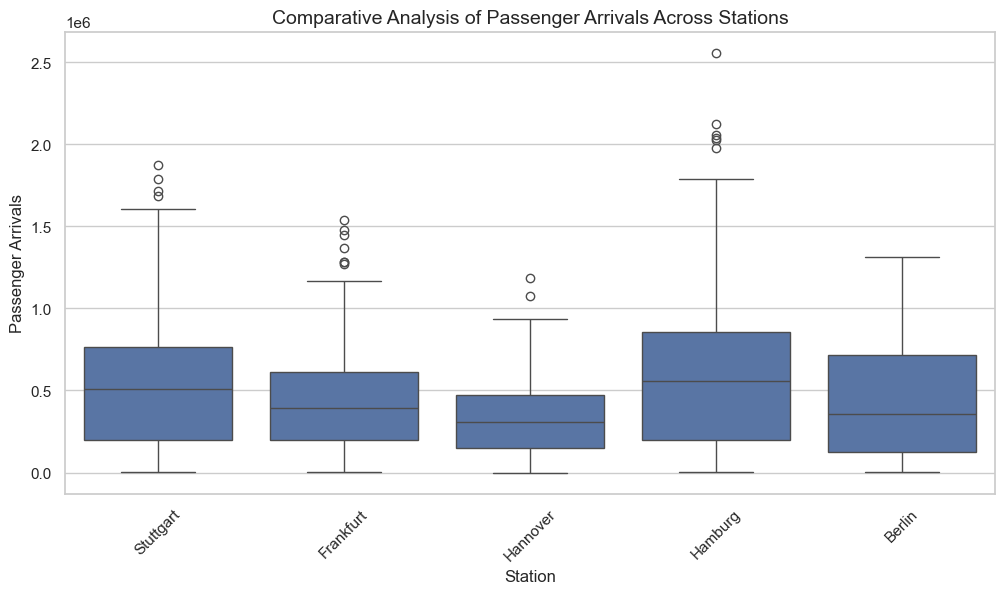

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('Stations_Data.csv', sep=';')

data['Passengers'] = pd.to_numeric(data['Passengers'].astype(str).str.replace(',', '.'))


sns.boxplot(x='Station', y='Passengers', data=data)
plt.title('Comparative Analysis of Passenger Arrivals Across Stations')
plt.xlabel('Stations')
plt.ylabel('Passenger Arrivals')
plt.show()

## 3.Analysis and Interpretation of Results


### 3.1 Visualization and Statistical Insights


The boxplot illustrates passenger arrival patterns for five stations: Stuttgart, Frankfurt, Hannover, Hamburg, and Berlin. Each box captures the middle 50% of the data, while outliers appear as isolated points beyond the whiskers. From the plot, it is evident that: • Hamburg shows the highest variability, with several extreme values. • Hannover and Frankfurt display lower medians and smaller spreads, suggesting lower and more stable arrivals. • Stuttgart and Hamburg have the highest medians, indicating that they are stations with the highest average passenger flow.

### 3.2 Interpretation in Context


These findings help identify stations with high operational demand or variability, supporting data-driven decisions such as: • Allocating additional train services to high-demand stations. • Investigating causes of irregular inflows. • Prioritizing infrastructure upgrades or congestion management based on load variability. The use of both visual and statistical tools provides a comprehensive perspective on passenger traffic across the network and strengthens the realism and analytical depth of the simulation system.

# US17

## 1. Detailed Description of the Objectives and Theoretical Concepts

### Objectives

The main goals of this analysis are as follows:

- To provide an interactive visualization of the distribution of specific cargo types.
- To identify monthly patterns using a user-driven interface.
- To present basic descriptive statistics to support informed decision-making.

### Theoretical Concepts

#### Adaptive Histograms

The binning strategy used in this analysis is based on NumPy's automatic method, which dynamically determines the number of intervals according to the data characteristics:

$$
\text{bins} = \text{auto (method of NumPy)}
$$

#### Descriptive Statistics

The implemented metrics include:

- **Mean**: The formula $$ ( \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i ) $$ represents the arithmetic mean of a dataset. It is calculated by summing all observed values and dividing the total by the number of observation. This measure provides a central value that summarizes the overall tendency of the data, helping to understand the general scale of cargo quantities arriving at a station.

- **Median**: The median is the value that separates a dataset into two equal halves. When all observations are sorted in ascending order, the median is the middle value if the number of elements is odd, or the average of the two central values if the number is even. Unlike the mean, the median is less sensitive to extreme values or outliers, making it a robust measure of central tendency.

- **Extremes**: the minimum and maximum values identified in the data.


## 2. Code

Write the station name:  Berlin


Types of cargo: Iron, Coal, Steel, Vegetables, Cereals, Wool, Coffee, Cattle


Write the cargo type:  Coal



Stats for Coal in  Berlin:
- Mean: 465.9 tons
- Median: 441.7 tons
- Maximum: 1575.3 tons
- Minimum: 0.2 tons


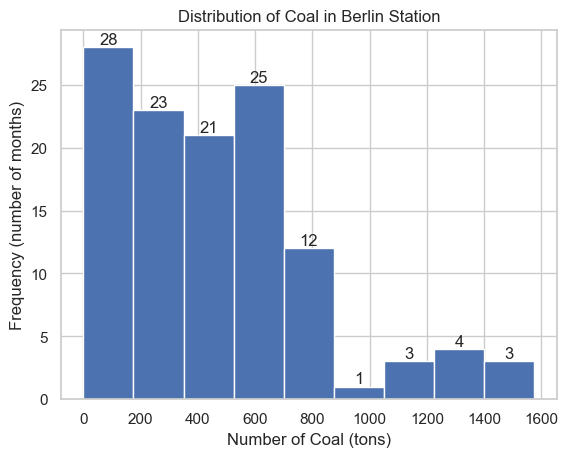

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Carregar os dados corretamente
data = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

# Lista de cargas disponíveis
cargos_disponiveis = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']

# Função de pedir dados

def pedir_dados_utilizador():
    # Pedir nome da estação
    station_name = input("Write the station name: ").strip()

    # Pedir tipo de carga
    print(f"Types of cargo: {', '.join(cargos_disponiveis)}")
    cargo_type = input("Write the cargo type: ").strip()
    
    while cargo_type not in cargos_disponiveis:
        print("Invalid cargo type")
        cargo_type = input("Write a valid cargo type: ").strip()

    return station_name, cargo_type

def generate_cargo_histogram(station_name, cargo_type):
    # Verificar se o tipo de carga é válido
    if cargo_type not in cargos_disponiveis:
        print(f"Invalid cargo type. Types: {', '.join(cargos_disponiveis)}")
        return
    
    # Filtrar por estação
    station_data = data[data['Station'] == station_name]
    
    if station_data.empty:
        print(f"Station '{station_name}' not found.")
        return
    
    # Converter para numérico
    cargo_data = pd.to_numeric(station_data[cargo_type], errors='coerce').dropna()
    
    if cargo_data.empty:
        print(f"No data available for {cargo_type} in {station_name}" )
        return
    
    # Histograma
    n, bins, patches = plt.hist(cargo_data, bins='auto', edgecolor='white', density=False)
    

    # Configurações do gráfico
    title = f'Distribution of {cargo_type} in {station_name} Station'
    plt.title(title)
    plt.xlabel(f'Number of {cargo_type} (tons)', fontsize=12)
    plt.ylabel('Frequency (number of months)', fontsize=12)
    
    # Adicionar contagem em cada barra
    for i in range(len(patches)):
        plt.text(patches[i].get_x() + patches[i].get_width()/2, 
                 patches[i].get_height(), 
                 str(int(n[i])), 
                 ha='center', va='bottom')

    # Mostrar estatísticas
    print(f"\nStats for {cargo_type} in  {station_name}:")
    
    mean_val = cargo_data.mean()
    median_val = cargo_data.median()
    
    print(f"- Mean: {mean_val:.1f} tons")
    print(f"- Median: {median_val:.1f} tons")
    print(f"- Maximum: {cargo_data.max():.1f} tons")
    print(f"- Minimum: {cargo_data.min():.1f} tons")
    
    plt.show()


# Uso

station, cargo = pedir_dados_utilizador()
generate_cargo_histogram(station, cargo)


## 3. Analysis and Interpretation of Results

### Implementation Features

The system developed for this analysis presents the following key functionalities:

- **Interactive interface**: Users are guided step-by-step to select parameters such as station name and cargo type.
- **Validation of input**: The program ensures that user inputs are checked for correctness, preventing runtime errors or invalid analysis.

### Processing Flow

1. The user provides the required inputs (station and cargo type).
2. The dataset is filtered accordingly to extract only the relevant records.
3. Basic statistical measures are computed for the selected data.
4. A histogram is produced, offering a visual interpretation of the distribution.

### Result Interpretation

[comment]: <> (LINK DA IMAGEM)

<a href="https://imgbb.com/"><img src="https://i.ibb.co/0jcxQddn/Histogram-Example.png" border="0"></a>

*Figure: Output example for the Berlin station, cargo: Coal*

The histogram associated with the quantity of **Coal** arriving at the **Berlin** station displays a distinct right-skewed distribution. The majority of monthly entries fall within the lower intervals (0 to 600 tons), while relatively few months reach significantly higher volumes, in some cases surpassing 1000 tons.

This skewness implies that while deliveries are generally stable and low in quantity, there are exceptional instances of high-volume inflows. These peaks might correspond to industrial events such as stockpiling operations, seasonal demands, or irregular supply chain adjustments.

Several inferences can be drawn from this pattern:

- **Operational irregularities**: The occasional spikes may reflect unplanned resupply events or delays followed by compensation deliveries.
- **Capacity limitations**: Regular lower values might suggest infrastructure constraints that only occasionally allow higher volumes.
- **Contextual influences**: Factors such as external economic shocks, industrial policy shifts, or maintenance operations might explain the observed variability.

From the standpoint of railway system simulation and planning, this type of insight is invaluable. Understanding the variability in cargo arrivals can support better train scheduling, appropriate resource allocation, and long-term infrastructure decisions.

Ultimately, the capacity to anticipate and interpret such fluctuations contributes to a more resilient and optimized logistics network.


# US18

## 1.
 This analysis aims to understand the distribution of three essential elements in railway operation - trains, passengers and mail - across the different stations. The idea is to provide a clear and intuitive view of how these elements are distributed along the railway network.

Theoretical Concepts

    Pie charts: Used to represent proportions of a whole. Each slice of the graph shows the percentage of an element (e.g. passengers) that corresponds to each station.

    Load Distribution: Refers to how the resources (trains, passengers, mail) are distributed among the stations.

    Grouping by Station: The data was grouped by station, adding up the totals for each variable of interest.

    This approach follows good data visualisation practices and is essential for supporting strategic decisions in railway network simulation.
    

## 2.Code

Colunas: ['Station', 'Year', 'Month', 'Arrivals', 'Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle', 'Passengers', 'Mail', 'Revenues', 'Expenses']


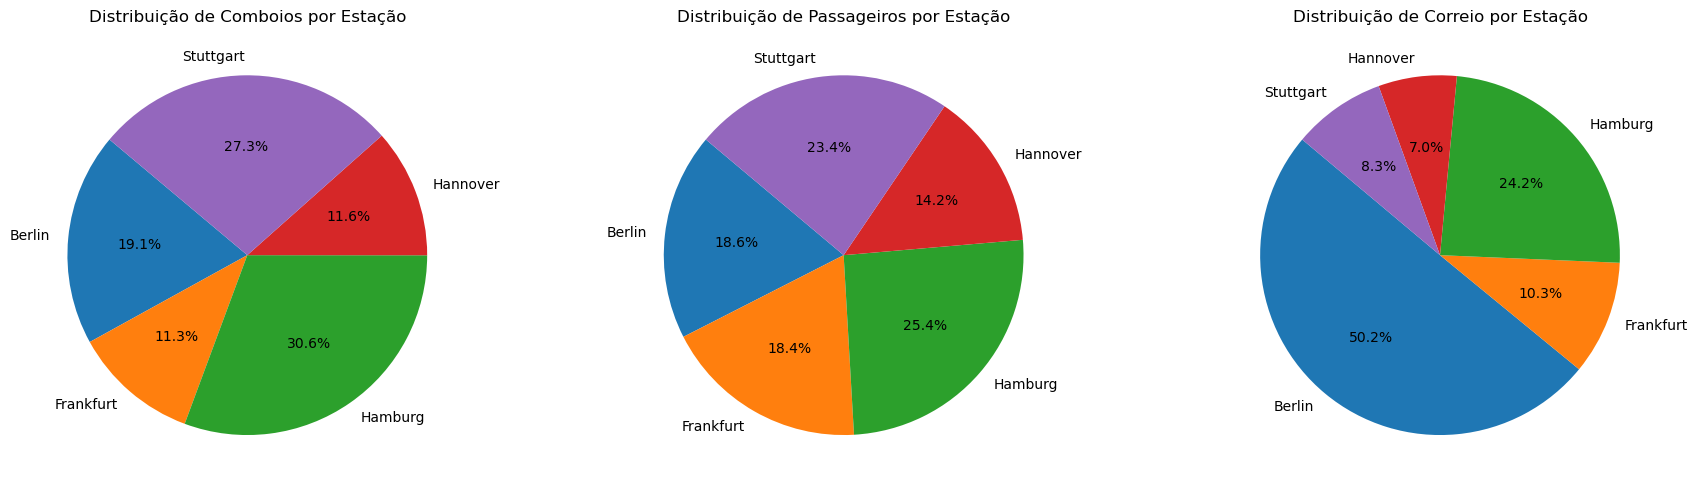

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregar o CSV com separador ;
df = pd.read_csv('Stations_Data.csv', sep=';')

# Remover espaços extras nos nomes das colunas
df.columns = df.columns.str.strip()

# Mostrar colunas para verificação
print("Colunas:", df.columns.tolist())

# Converter vírgulas para pontos nas colunas numéricas e transformar em float
colunas_numericas = ['Arrivals', 'Passengers', 'Mail', 'Revenues', 'Expenses']
for col in colunas_numericas:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

# Calcular lucro da estação
df['Profit'] = df['Revenues'] - df['Expenses']

# Verificar os primeiros dados
df.head()

# Agrupar por estação somando valores de interesse
distribuicao = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum()

# Visualizar dados agregados
distribuicao

# Tamanho da figura
plt.figure(figsize=(18, 5))

# Gráfico 1: Distribuição de comboios (Arrivals)
plt.subplot(1, 3, 1)
plt.pie(distribuicao['Arrivals'], labels=distribuicao.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribuição de Comboios por Estação')

# Gráfico 2: Passageiros
plt.subplot(1, 3, 2)
plt.pie(distribuicao['Passengers'], labels=distribuicao.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribuição de Passageiros por Estação')

# Gráfico 3: Correio
plt.subplot(1, 3, 3)
plt.pie(distribuicao['Mail'], labels=distribuicao.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribuição de Correio por Estação')

# Ajustar layout
plt.tight_layout()
plt.show()

## 3.

Interpreting and analysing the results

    From the pie charts generated, you can clearly see which stations are most important for train traffic, passenger transport and mail handling.

Observations:

    Stations with larger slices represent a greater workload, i.e. they receive more trains, passengers or mail.

    Stations with a high volume of passengers may indicate important urban centres or popular destinations.

    Stations with a lot of mail may be associated with administrative or logistics centres.
